In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.signal import savgol_filter
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy import sparse
from scipy.sparse.linalg import spsolve



normiertes Ramanspektrum für Referenzprobe - CNT - auf Steg - Rohdaten

[-261.97517861 -260.94645795 -259.91773729 ... 4348.7185375  4349.63339699
 4350.54825647]
[0.00964535 0.01001432 0.01431176 ... 0.00435387 0.00737075 0.00451882]


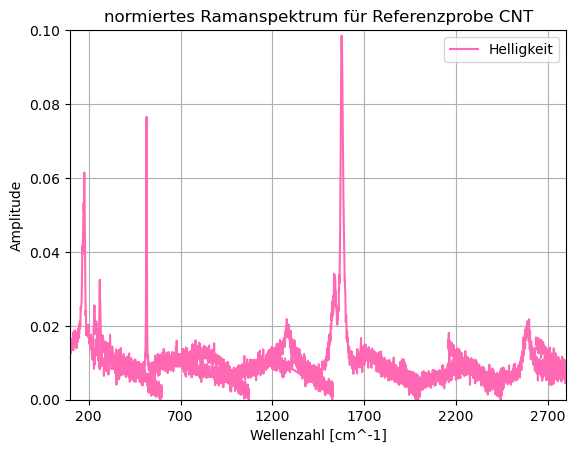

In [17]:
# Rohdaten einlesen

messdaten_auf_kreuz= np.genfromtxt(
    'Referenzprobe CNT - auf Kreuz.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)

wellenzahl_cm = messdaten_auf_kreuz[:,0]
amplitude = messdaten_auf_kreuz[:,1]

# Überprüfung des Einlesens und Speicherns
print(wellenzahl_cm)
print(amplitude)

# Plot nur im wichtigen Bereich (ohne Rayleight und Ende Spektrum)
plt.plot(wellenzahl_cm, amplitude, color='hotpink', label='Helligkeit')
plt.xticks(np.arange(-300, 5000, 500))  
plt.xlim(100,2800)
plt.ylim(0,0.1)
plt.title('normiertes Ramanspektrum für Referenzprobe CNT')
plt.xlabel('Wellenzahl [cm^-1]')
plt.ylabel('Amplitude') 
plt.legend()
plt.grid(True)
plt.show()

normiertes Ramanspektrum für Referenzprobe - CNT - auf Steg - RBM

-> Fit mit gedämpftem Rot und starkem Orange erfolgreich!
Berechnete Halbwertsbreiten (FWHM):
RBM 1  (Hauptpeak): FWHM = 11.00 cm⁻¹  (gamma = 5.50)
Si-2TA (Substrat):  FWHM = 9.00 cm⁻¹  (gamma = 4.50)
RBM 2  (Rechts):    FWHM = 14.00 cm⁻¹  (gamma = 7.00)


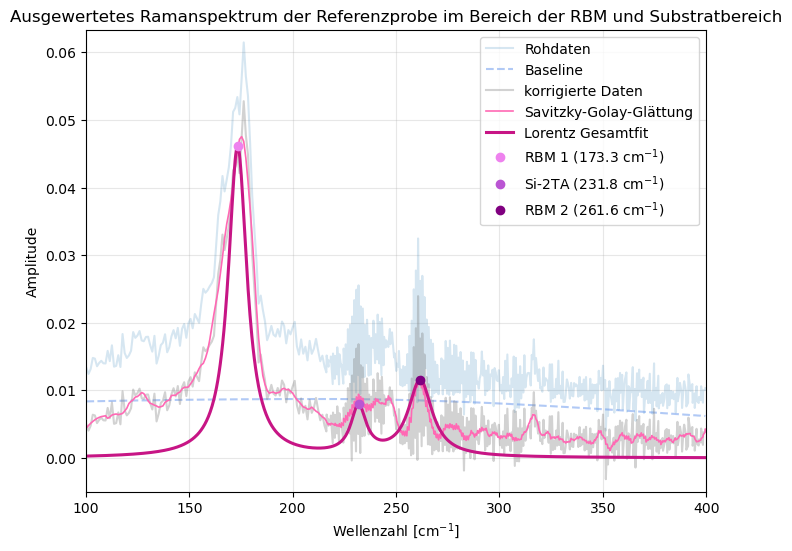

In [18]:
# Rohdaten einlesen und sortieren
messdaten_auf_kreuz= np.genfromtxt(
    'Referenzprobe CNT - auf Kreuz.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)

wellenzahl_cm = messdaten_auf_kreuz[:,0]
amplitude = messdaten_auf_kreuz[:,1]

idx = np.argsort(wellenzahl_cm)
wellenzahl_cm = wellenzahl_cm[idx]
amplitude = amplitude[idx]

# Baseline-Funktion (ALS)
def baseline_als(y, lam=1e6, p=0.01, niter=10):
    L = len(y)
    D = sparse.diags([1, -2, 1], [0, -1, -2], shape=(L, L))
    w = np.ones(L)

    for i in range(niter):
        W = sparse.diags(w, 0)
        Z = W + lam * D.dot(D.T)
        z = spsolve(Z, w * y)
        w = p * (y > z) + (1 - p) * (y < z)

    return z

# Basis-Lorentz-Funktion
def lorentz(x, A, x0, gamma):
    return A * (gamma**2 / ((x - x0)**2 + gamma**2))

# --- NEU: Triple-Lorentz-Funktion für alle drei Peaks gleichzeitig ---
def triple_lorentz(x, A1, x0_1, g1, A2, x0_2, g2, A3, x0_3, g3):
    return (lorentz(x, A1, x0_1, g1) + 
            lorentz(x, A2, x0_2, g2) + 
            lorentz(x, A3, x0_3, g3))

# Baseline und Glättung
baseline_full = baseline_als(amplitude, lam=1e8, p=0.01)

# Beschränkung x-Achse auf das RBM-Fenster (100 bis 400 cm⁻¹)
mask = (wellenzahl_cm >= 100) & (wellenzahl_cm <= 400)

wellenzahl_cut = wellenzahl_cm[mask]
amplitude_cut = amplitude[mask]
baseline_cut = baseline_full[mask] 

corrected_cut = amplitude_cut - baseline_cut

window_length = 15  
polyorder = 2

if len(corrected_cut) < window_length:
    window_length = len(corrected_cut) if len(corrected_cut) % 2 != 0 else len(corrected_cut) - 1

smoothed_cut = savgol_filter(corrected_cut, window_length=window_length, polyorder=polyorder)

fit_mask = (wellenzahl_cut >= 140) & (wellenzahl_cut <= 290)
x_fit = wellenzahl_cut[fit_mask]
y_fit = corrected_cut[fit_mask]

x0_1_fixed = 173.3  

mask_zacken1 = (wellenzahl_cut >= 230) & (wellenzahl_cut <= 240)
x0_2_fixed = wellenzahl_cut[mask_zacken1][np.argmax(smoothed_cut[mask_zacken1])]

mask_zacken2 = (wellenzahl_cut >= 255) & (wellenzahl_cut <= 263)
x0_3_fixed = wellenzahl_cut[mask_zacken2][np.argmax(smoothed_cut[mask_zacken2])]

# Hilfsfunktion (Positionen fest)
def triple_lorentz_fixed_x(x, A1, g1, A2, g2, A3, g3):
    return (lorentz(x, A1, x0_1_fixed, g1) + 
            lorentz(x, A2, x0_2_fixed, g2) + 
            lorentz(x, A3, x0_3_fixed, g3))
p0 = [
    0.040, 5.0,   
    0.006, 3.5,   
    0.012, 3.5    
]
lower_bounds = [
    0.030, 3.0,   
    0.003, 1.5,   
    0.009, 1.5    
]
upper_bounds = [
    0.046, 5.5,   
    0.007, 4.5,   
    0.018, 7.0    
]

try:
    popt_mini, _ = curve_fit(triple_lorentz_fixed_x, x_fit, y_fit, p0=p0, bounds=(lower_bounds, upper_bounds))
    
    popt_rbm = np.array([
        popt_mini[0], x0_1_fixed, popt_mini[1],  # RBM 1
        popt_mini[2], x0_2_fixed, popt_mini[3],  # Si-2TA
        popt_mini[4], x0_3_fixed, popt_mini[5]   # RBM 2
    ])
    print("-> Fit mit gedämpftem Rot und starkem Orange erfolgreich!")
    plot_fit = True
except Exception as e:
    print(f"Fehler beim Fit: {e}")
    plot_fit = False

params_rbm_triple = popt_rbm.copy()

if plot_fit:
    gamma_rbm1  = popt_rbm[2]
    gamma_si2ta = popt_rbm[5]
    gamma_rbm2  = popt_rbm[8]
    
    fwhm_rbm1  = 2 * gamma_rbm1
    fwhm_si2ta = 2 * gamma_si2ta
    fwhm_rbm2  = 2 * gamma_rbm2
    
    
    print("Berechnete Halbwertsbreiten (FWHM):")
    print(f"RBM 1  (Hauptpeak): FWHM = {fwhm_rbm1:.2f} cm⁻¹  (gamma = {gamma_rbm1:.2f})")
    print(f"Si-2TA (Substrat):  FWHM = {fwhm_si2ta:.2f} cm⁻¹  (gamma = {gamma_si2ta:.2f})")
    print(f"RBM 2  (Rechts):    FWHM = {fwhm_rbm2:.2f} cm⁻¹  (gamma = {gamma_rbm2:.2f})")
    

# Plot
plt.figure(figsize=(8, 6))
plt.xlim(100, 400)
plt.ylim(-0.005, np.max(corrected_cut) * 1.2)

# Hintergrund-Kurven
plt.plot(wellenzahl_cut, amplitude_cut, 'tab:blue', alpha=0.18, label="Rohdaten")
plt.plot(wellenzahl_cut, baseline_cut, linestyle='--', color='cornflowerblue', alpha=0.5, label="Baseline")
plt.plot(wellenzahl_cut, corrected_cut, 'tab:gray', alpha=0.35, label="korrigierte Daten")
plt.plot(wellenzahl_cut, smoothed_cut, color='hotpink', linewidth=1.2, label="Savitzky-Golay-Glättung")

# Kontinuierliche x-Achse für eine mathematisch glatte Fit-Darstellung
x_plot = np.linspace(100, 400, 1000)

if plot_fit:
    # Einzelkomponenten berechnen (für gestrichelte Linien im Plot)
    y_rbm1 = lorentz(x_plot, *popt_rbm[0:3])
    y_si2ta = lorentz(x_plot, *popt_rbm[3:6])
    y_rbm2 = lorentz(x_plot, *popt_rbm[6:9])
    
    # Gesamtes mathematisch addiertes Modell
    y_gesamt_modell = triple_lorentz(x_plot, *popt_rbm)
    
    # Einzelne Komponenten einzeichnen
    #plt.plot(x_plot, y_rbm1, color='crimson', linestyle=':', linewidth=1.5, label='Komponente RBM 1')
    #plt.plot(x_plot, y_si2ta, color='forestgreen', linestyle=':', linewidth=1.5, label='Komponente Si-2TA')
    #plt.plot(x_plot, y_rbm2, color='darkorange', linestyle=':', linewidth=1.5, label='Komponente RBM 2')
    
    # Gesamte Fit-Kurve zeichnen
    plt.plot(x_plot, y_gesamt_modell, color='mediumvioletred', linewidth=2.2, label='Lorentz Gesamtfit')
    
    # Exakte mathematische Y-Höhen auf der addierten Gesamtkurve berechnen
    y_punkt1 = triple_lorentz(popt_rbm[1], *popt_rbm)
    y_punkt2 = triple_lorentz(popt_rbm[4], *popt_rbm)
    y_punkt3 = triple_lorentz(popt_rbm[7], *popt_rbm)
    
    # Peakspitzen exakt auf der Kurve markieren
    plt.plot(popt_rbm[1], y_punkt1, color='violet', marker='o', linestyle='none', zorder=5,
             label=f'RBM 1 ({popt_rbm[1]:.1f} cm$^{{-1}}$)')
    plt.plot(popt_rbm[4], y_punkt2, color='mediumorchid', marker='o', linestyle='none', zorder=5,
             label=f'Si-2TA ({popt_rbm[4]:.1f} cm$^{{-1}}$)')
    plt.plot(popt_rbm[7], y_punkt3, color='purple', marker='o', linestyle='none', zorder=5,
             label=f'RBM 2 ({popt_rbm[7]:.1f} cm$^{{-1}}$)')

plt.title('Ausgewertetes Ramanspektrum der Referenzprobe im Bereich der RBM und Substratbereich')
plt.xlabel('Wellenzahl [cm$^{-1}$]')
plt.ylabel('Amplitude') 
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.show()

Echtes physikalisches Maximum gefunden bei: 515.39 cm⁻¹
Fit erfolgreich! Parameter: Amplitude=0.0719, Position=515.10 cm⁻¹, Gamma=0.95
Berechnete Halbwertsbreite (FWHM):
Si-TO Substratpeak: FWHM = 1.91 cm⁻¹  (gamma = 0.95)


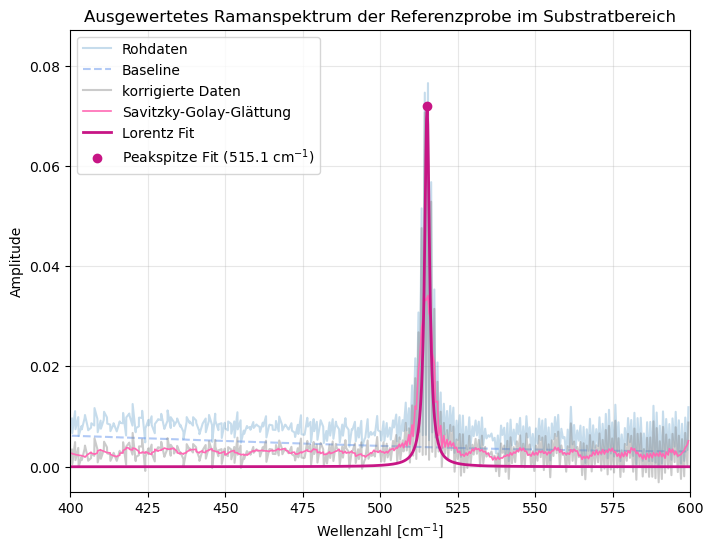

In [19]:
# Rohdaten einlesen und sortieren
messdaten_auf_kreuz= np.genfromtxt(
    'Referenzprobe CNT - auf Kreuz.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)

wellenzahl_cm = messdaten_auf_kreuz[:,0]
amplitude = messdaten_auf_kreuz[:,1]

idx = np.argsort(wellenzahl_cm)
wellenzahl_cm = wellenzahl_cm[idx]
amplitude = amplitude[idx]

# Baseline-Funktion (ALS)
def baseline_als(y, lam=1e8, p=0.01, niter=10):
    L = len(y)
    D = sparse.diags([1, -2, 1], [0, -1, -2], shape=(L, L))
    w = np.ones(L)

    for i in range(niter):
        W = sparse.diags(w, 0)
        Z = W + lam * D.dot(D.T)
        z = spsolve(Z, w * y)
        w = p * (y > z) + (1 - p) * (y < z)

    return z

# Lorentz-Funktion
def lorentz(x, A, x0, gamma):
    return A * (gamma**2 / ((x - x0)**2 + gamma**2))

# Baseline über das gesamte Spektrum berechnen
baseline_full = baseline_als(amplitude, lam=1e8, p=0.01)

# Beschränkung auf das Si-TO-Fenster
mask = (wellenzahl_cm >= 400) & (wellenzahl_cm <= 600)

wellenzahl_cut = wellenzahl_cm[mask]
amplitude_cut = amplitude[mask]
baseline_cut = baseline_full[mask] 

# Korrektur der Rohdaten (Baseline-Abzug)
corrected_cut = amplitude_cut - baseline_cut

# Savitzky-Golay Glättung
window_length = 15  
polyorder = 2

if len(corrected_cut) < window_length:
    window_length = len(corrected_cut) if len(corrected_cut) % 2 != 0 else len(corrected_cut) - 1

smoothed_cut = savgol_filter(corrected_cut, window_length=window_length, polyorder=polyorder)

# Peak-Finding auf den geglätteten Daten
peaks, _ = find_peaks(smoothed_cut, prominence=0.002)

if len(peaks) < 1:
    raise ValueError("Kein Peak im Bereich gefunden!")

# Grobes Zentrum bestimmen
main_peak_idx = peaks[np.argmax(smoothed_cut[peaks])]
peak_center_grob = wellenzahl_cut[main_peak_idx]

# Suche nach dem ungeglätteten Maximum in direkter Umgebung
search_area = (wellenzahl_cut >= peak_center_grob - 5) & (wellenzahl_cut <= peak_center_grob + 5)
real_max_amp = np.max(corrected_cut[search_area])
real_max_welle = wellenzahl_cut[search_area][np.argmax(corrected_cut[search_area])]

print(f"Echtes physikalisches Maximum gefunden bei: {real_max_welle:.2f} cm⁻¹")

# Fit-Maske eng um das wahre Maximum legen (+- 15 cm^-1)
fit_mask = (wellenzahl_cut >= real_max_welle - 15) & (wellenzahl_cut <= real_max_welle + 15)

x_fit = wellenzahl_cut[fit_mask]
y_fit = corrected_cut[fit_mask]  # Wir fitten die ungestauchten korrigierten Daten

# Startwerte: [Amplitude, Position, Halbwertsbreite]
p0 = [real_max_amp, real_max_welle, 4]

# Grenzen definieren: Die Amplitude DARF mathematisch nicht unter 99% des Peaks fallen
lower_bounds = [real_max_amp * 0.99, real_max_welle - 2, 0.5]
upper_bounds = [real_max_amp * 1.05, real_max_welle + 2, 12]

try:
    params, _ = curve_fit(
        lorentz, 
        x_fit, 
        y_fit, 
        p0=p0, 
        bounds=(lower_bounds, upper_bounds), 
        maxfev=10000
    )
    print(f"Fit erfolgreich! Parameter: Amplitude={params[0]:.4f}, Position={params[1]:.2f} cm⁻¹, Gamma={params[2]:.2f}")
    plot_fit = True
except Exception as e:
    print(f"WARNUNG: Mathematischer Fit blockiert ({e}). Nutze Fallback-Maximum.")
    params = np.array([real_max_amp, real_max_welle, 4.0])
    plot_fit = True

# Parameter für das Gesamtspektrum später
params_si_to = params.copy()

gamma_si_to = params[2]
fwhm_si_to = 2 * gamma_si_to

print("Berechnete Halbwertsbreite (FWHM):")
print(f"Si-TO Substratpeak: FWHM = {fwhm_si_to:.2f} cm⁻¹  (gamma = {gamma_si_to:.2f})")

# Plot
plt.figure(figsize=(8, 6))
plt.xlim(400, 600)
plt.ylim(-0.005, np.max(corrected_cut) * 1.2)

# Daten-Kurven
plt.plot(wellenzahl_cut, amplitude_cut, 'tab:blue', alpha=0.25, label="Rohdaten")
plt.plot(wellenzahl_cut, baseline_cut, linestyle='--', color='cornflowerblue', alpha=0.5, label="Baseline")
plt.plot(wellenzahl_cut, corrected_cut, 'tab:gray', alpha=0.4, label="korrigierte Daten")
plt.plot(wellenzahl_cut, smoothed_cut, color='hotpink', linewidth=1.2, label="Savitzky-Golay-Glättung")

if plot_fit:
    x_plot = np.linspace(400, 600, 1000)
    plt.plot(x_plot, lorentz(x_plot, *params), color='mediumvioletred', label='Lorentz Fit', linewidth=2)
    plt.plot(params[1], params[0], color='mediumvioletred', marker='o', linestyle='none', zorder=5,
             label=f'Peakspitze Fit ({params[1]:.1f} cm$^{{-1}}$)')

plt.title('Ausgewertetes Ramanspektrum der Referenzprobe im Substratbereich')
plt.xlabel('Wellenzahl [cm$^{-1}$]')
plt.ylabel('Amplitude') 
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.show()

C:\Users\nelln\AppData\Local\Temp\ipykernel_32396\1366302971.py:25: SparseEfficiencyWarning: spsolve requires A be CSC or CSR matrix format
  z = spsolve(Z, w * y)


-> Globaler Multi-Peak-Fit erfolgreich!
   D-Band:  Zentrum = 1280.34 cm⁻¹, Amplitude = 0.0093, Gamma = 88.89
   G⁻-Band: Zentrum = 1539.95 cm⁻¹, Amplitude = 0.0233, Gamma = 7.21
   G⁺-Band: Zentrum = 1578.50 cm⁻¹, Amplitude = 0.0883, Gamma = 9.83
Berechnete Halbwertsbreiten (FWHM):
D-Band:  FWHM = 177.78 cm⁻¹  (gamma = 88.89)
G⁻-Band: FWHM = 14.41 cm⁻¹  (gamma = 7.21)
G⁺-Band: FWHM = 19.66 cm⁻¹  (gamma = 9.83)


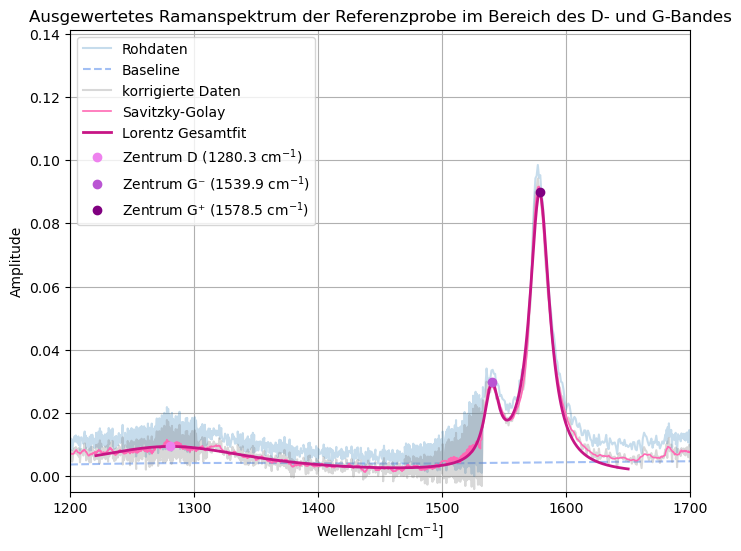

In [61]:
# Rohdaten einlesen und sortieren
messdaten_auf_kreuz = np.genfromtxt('Referenzprobe CNT - auf Kreuz.txt', delimiter='\t', 
    converters={
        0: lambda s: float(s.replace(',', '.')), # Konvertierung 1. Spalte
        1: lambda s: float(s.replace(',', '.')) # Konvertierung 2. Spalte
    }
)

wellenzahl_cm = messdaten_auf_kreuz[:,0]
amplitude = messdaten_auf_kreuz[:,1]

idx = np.argsort(wellenzahl_cm)
wellenzahl_cm = wellenzahl_cm[idx]
amplitude = amplitude[idx]

# Baseline-Funktion (ALS)
def baseline_als(y, lam=1e8, p=0.01, niter=10):
    L = len(y)
    D = sparse.diags([1, -2, 1], [0, -1, -2], shape=(L, L))
    w = np.ones(L)

    for i in range(niter):
        W = sparse.diags(w, 0)
        Z = W + lam * D.dot(D.T)
        z = spsolve(Z, w * y)
        w = p * (y > z) + (1 - p) * (y < z)

    return z

# Lorentz-Funktion
def lorentz(x, A, x0, gamma):
    return A * (gamma**2 / ((x - x0)**2 + gamma**2))

# Multi-Lorentz-Funktion für das gleichzeitige Fitten von 3 Peaks
def multi_lorentz(x, A1, x0_1, g1, A2, x0_2, g2, A3, x0_3, g3):
    return (lorentz(x, A1, x0_1, g1) + 
            lorentz(x, A2, x0_2, g2) + 
            lorentz(x, A3, x0_3, g3))

# Baseline und Glättung
baseline_full = baseline_als(amplitude, lam=1e8, p=0.01)

# Maske um ausgewählten Bereich
mask = (wellenzahl_cm >= 1100) & (wellenzahl_cm <= 1800)
wellenzahl_cut = wellenzahl_cm[mask]
amplitude_cut = amplitude[mask]
baseline_cut = baseline_full[mask] 

corrected_cut = amplitude_cut - baseline_cut

window_length = 15  
polyorder = 2
if len(corrected_cut) < window_length:
    window_length = len(corrected_cut) if len(corrected_cut) % 2 != 0 else len(corrected_cut) - 1

smoothed_cut = savgol_filter(corrected_cut, window_length=window_length, polyorder=polyorder)

# grobe Peak Abschätzung zum Finden der Peaks
bereiche = [
    (1240, 1340),  # D-Band
    (1520, 1555),  # G⁻-Band
    (1555, 1610)   # G⁺-Band
]

start_peaks = []
start_amps = []

for untergrenze, obergrenze in bereiche:
    b_mask = (wellenzahl_cut >= untergrenze) & (wellenzahl_cut <= obergrenze)
    sub_amp = smoothed_cut[b_mask]
    sub_welle = wellenzahl_cut[b_mask]
    max_idx = np.argmax(sub_amp)
    start_peaks.append(sub_welle[max_idx])
    start_amps.append(sub_amp[max_idx])

# Fit des gesamten relevanten Spektrums auf einmal
fit_mask = (wellenzahl_cut >= 1220) & (wellenzahl_cut <= 1650)
x_fit = wellenzahl_cut[fit_mask]
y_fit = smoothed_cut[fit_mask]

# Startwerte: [A1, x0_1, g1, A2, x0_2, g2, A3, x0_3, g3]
p0 = [
    start_amps[0], start_peaks[0], 25,  # D-Band Startwerte (breiter)
    start_amps[1], start_peaks[1], 10,  # G⁻-Band Startwerte
    start_amps[2], start_peaks[2], 6    # G⁺-Band Startwerte (scharf)
]

try:
    # globaler Fit
    popt, _ = curve_fit(multi_lorentz, x_fit, y_fit, p0=p0, maxfev=10000)
    print("-> Globaler Multi-Peak-Fit erfolgreich!")
    print(f"   D-Band:  Zentrum = {popt[1]:.2f} cm⁻¹, Amplitude = {popt[0]:.4f}, Gamma = {popt[2]:.2f}")
    print(f"   G⁻-Band: Zentrum = {popt[4]:.2f} cm⁻¹, Amplitude = {popt[3]:.4f}, Gamma = {popt[5]:.2f}")
    print(f"   G⁺-Band: Zentrum = {popt[7]:.2f} cm⁻¹, Amplitude = {popt[6]:.4f}, Gamma = {popt[8]:.2f}")
except Exception as e:
    print(f"-> FEHLER beim globalen Fit: {e}")
    popt = None
    
if popt is not None:
    # popt enthält: [A_d, x0_d, g_d, A_gneg, x0_gneg, g_gneg, A_gpos, x0_gpos, g_gpos]
    params_d     = popt[0:3]  # Holt die Werte 0, 1, 2 (D-Band)
    params_g_neg = popt[3:6]  
    params_g_pos = popt[6:9] 
    
    fwhm_d     = 2 * popt[2]
    fwhm_g_neg = 2 * popt[5]
    fwhm_g_pos = 2 * popt[8]
    
    
    print("Berechnete Halbwertsbreiten (FWHM):")
    print(f"D-Band:  FWHM = {fwhm_d:.2f} cm⁻¹  (gamma = {popt[2]:.2f})")
    print(f"G⁻-Band: FWHM = {fwhm_g_neg:.2f} cm⁻¹  (gamma = {popt[5]:.2f})")
    print(f"G⁺-Band: FWHM = {fwhm_g_pos:.2f} cm⁻¹  (gamma = {popt[8]:.2f})")

else:
    params_d = params_g_neg = params_g_pos = None

# Plot
plt.figure(figsize=(8, 6))
plt.xlim(1200, 1700)
plt.ylim(-0.005, np.max(corrected_cut) * 1.5)

plt.plot(wellenzahl_cut, amplitude_cut, 'tab:blue', alpha=0.25, label="Rohdaten")
plt.plot(wellenzahl_cut, baseline_cut, linestyle='--', color='cornflowerblue', alpha=0.6, label="Baseline")
plt.plot(wellenzahl_cut, corrected_cut, 'tab:gray', alpha=0.3, label="korrigierte Daten")
plt.plot(wellenzahl_cut, smoothed_cut, color='hotpink', linewidth=1.2, label="Savitzky-Golay")

if popt is not None:
    # Berechne die einzelnen Komponenten auf der Fit-Achse
    y_d = lorentz(x_fit, popt[0], popt[1], popt[2])
    y_g_neg = lorentz(x_fit, popt[3], popt[4], popt[5])
    y_g_pos = lorentz(x_fit, popt[6], popt[7], popt[8])
    y_gesamt = multi_lorentz(x_fit, *popt)

    # 1. Gesamte Fit-Kurve zeichnen (jetzt sicher im IF-Block)
    plt.plot(x_fit, y_gesamt, color='mediumvioletred', linewidth=2, label='Lorentz Gesamtfit')
        
    # 2. Exakte Y-Werte auf der SUMMIERTEN Gesamtkurve berechnen
    y_punkt_d     = multi_lorentz(popt[1], *popt)
    y_punkt_g_neg = multi_lorentz(popt[4], *popt)
    y_punkt_g_pos = multi_lorentz(popt[7], *popt)

    # 3. Punkte exakt auf der Gesamtkurve plotten
    plt.plot(popt[1], y_punkt_d, marker='o', color='violet', linestyle='none', 
             label=f'Zentrum D ({popt[1]:.1f} cm$^{{-1}}$)')
    plt.plot(popt[4], y_punkt_g_neg, marker='o', color='mediumorchid', linestyle='none', 
             label=f'Zentrum G⁻ ({popt[4]:.1f} cm$^{{-1}}$)')
    plt.plot(popt[7], y_punkt_g_pos, marker='o', color='purple', linestyle='none', 
             label=f'Zentrum G⁺ ({popt[7]:.1f} cm$^{{-1}}$)')

plt.title('Ausgewertetes Ramanspektrum der Referenzprobe im Bereich des D- und G-Bandes')
plt.xlabel('Wellenzahl [cm$^{-1}$]')
plt.ylabel('Amplitude') 
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

C:\Users\nelln\AppData\Local\Temp\ipykernel_32396\1405267243.py:26: SparseEfficiencyWarning: spsolve requires A be CSC or CSR matrix format
  z = spsolve(Z, w * y)


Hauptpeak gefunden bei: 2585.81 cm⁻¹
Fit erfolgreich! Parameter: Amplitude=0.0123, Position=2587.67 cm⁻¹, Gamma=23.93
Berechnete Halbwertsbreite (FWHM):
2D-Band Peak: FWHM = 47.86 cm⁻¹  (gamma = 23.93)


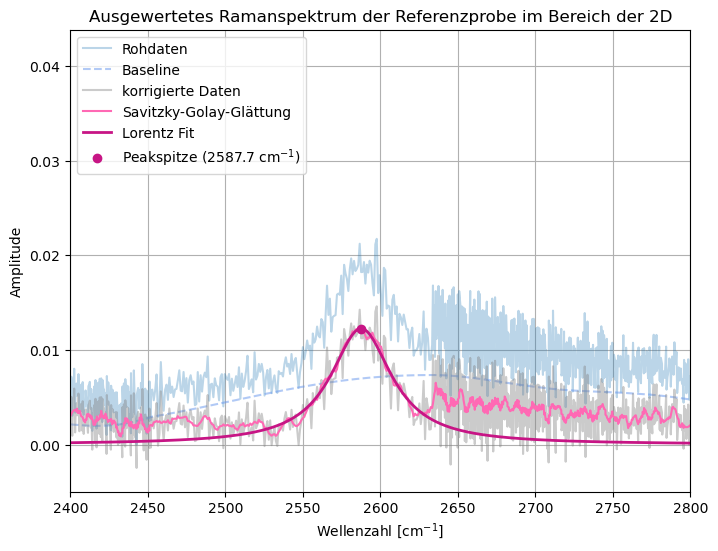

In [62]:
# Rohdaten einlesen und sortieren
messdaten_auf_kreuz = np.genfromtxt('Referenzprobe CNT - auf Kreuz.txt', delimiter='\t', 
    converters={
        0: lambda s: float(s.replace(',', '.')), # Konvertierung 1. Spalte
        1: lambda s: float(s.replace(',', '.')) # Konvertierung 2. Spalte
    }
)

wellenzahl_cm = messdaten_auf_kreuz[:,0]
amplitude = messdaten_auf_kreuz[:,1]

idx = np.argsort(wellenzahl_cm)
wellenzahl_cm = wellenzahl_cm[idx]
amplitude = amplitude[idx]

# Baseline-Funktion
def baseline_als(y, lam=1e6, p=0.01, niter=10):
    L = len(y)
    D = sparse.diags([1, -2, 1], [0, -1, -2], shape=(L, L))
    w = np.ones(L)

    for i in range(niter):
        W = sparse.diags(w, 0)
        Z = W + lam * D.dot(D.T)
        z = spsolve(Z, w * y)
        w = p * (y > z) + (1 - p) * (y < z)

    return z

# Baseline über das gesamte Spektrum
baseline_full = baseline_als(amplitude, lam=1e6, p=0.01)

# Beschränkung x-Achse
mask = (wellenzahl_cm >= 2400) & (wellenzahl_cm <= 2800)

wellenzahl_cut = wellenzahl_cm[mask]
amplitude_cut = amplitude[mask]
baseline_cut = baseline_full[mask] 

# Korrektur der Rohdaten (Baseline-Abzug)
corrected_cut = amplitude_cut - baseline_cut

# Savitzky-Golay Glättung
window_length = 15  
polyorder = 2

# Falls das Datenfeld zu kurz für das Fenster ist, fangen wir das hier ab
if len(corrected_cut) < window_length:
    window_length = len(corrected_cut) if len(corrected_cut) % 2 != 0 else len(corrected_cut) - 1

smoothed_cut = savgol_filter(corrected_cut, window_length=window_length, polyorder=polyorder)
# ------------------------------------

# Peak-Finding auf dem GLÄTTETEN Signal
peaks, _ = find_peaks(smoothed_cut, prominence=0.002)

if len(peaks) < 1:
    raise ValueError("Kein Peak im Bereich gefunden!")

peak_heights = smoothed_cut[peaks]
main_peak_idx = peaks[np.argmax(peak_heights)] 
peak_center = wellenzahl_cut[main_peak_idx]

print(f"Hauptpeak gefunden bei: {peak_center:.2f} cm⁻¹")

# Lorentz-Fit
def lorentz(x, A, x0, gamma):
    return A * (gamma**2 / ((x - x0)**2 + gamma**2))

p_mask = (wellenzahl_cut >= peak_center - 35) & \
         (wellenzahl_cut <= peak_center + 35)

x_fit, y_fit = wellenzahl_cut[p_mask], smoothed_cut[p_mask]

# Startwerte: [Amplitude, Position, Halbwertsbreite]
p0 = [np.max(y_fit), peak_center, 8] 

try:
    params, _ = curve_fit(lorentz, x_fit, y_fit, p0=p0, maxfev=5000)
    print(f"Fit erfolgreich! Parameter: Amplitude={params[0]:.4f}, Position={params[1]:.2f} cm⁻¹, Gamma={params[2]:.2f}")
    plot_fit = True
except Exception as e:
    print(f"WARNUNG: Lorentz-Fit fehlgeschlagen! Grund: {e}")
    plot_fit = False

# Speichern Parameter für Gesamtspektrum später
params_2d = params.copy()

if plot_fit:
    gamma_2d = params[2]
    fwhm_2d = 2 * gamma_2d
    
    
    print("Berechnete Halbwertsbreite (FWHM):")
    print(f"2D-Band Peak: FWHM = {fwhm_2d:.2f} cm⁻¹  (gamma = {gamma_2d:.2f})")
    
    
# Plot
plt.figure(figsize=(8, 6))
plt.xlim(2400, 2800)
plt.ylim(-0.005, np.max(corrected_cut) * 3)

plt.plot(wellenzahl_cut, amplitude_cut, 'tab:blue', alpha=0.3, label="Rohdaten")
plt.plot(wellenzahl_cut, baseline_cut, linestyle = '--', color = 'cornflowerblue', alpha=0.5, label="Baseline")
plt.plot(wellenzahl_cut, corrected_cut, 'tab:gray', alpha=0.4, label="korrigierte Daten")
plt.plot(wellenzahl_cut, smoothed_cut, color = 'hotpink', linewidth=1.5, label="Savitzky-Golay-Glättung")

if plot_fit:
    plt.plot(wellenzahl_cut, lorentz(wellenzahl_cut, *params), color = 'mediumvioletred', label='Lorentz Fit', linewidth=2)
    # Kleiner Punkt auf der berechneten Peakspitze zur Kontrolle
    plt.plot(params[1], params[0], color = 'mediumvioletred', marker = 'o', linestyle = 'none', label=f'Peakspitze ({params[1]:.1f} cm$^{{-1}}$)')

plt.title('Ausgewertetes Ramanspektrum der Referenzprobe im Bereich der 2D')
plt.xlabel('Wellenzahl [cm$^{-1}$]')
plt.ylabel('Amplitude') 
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

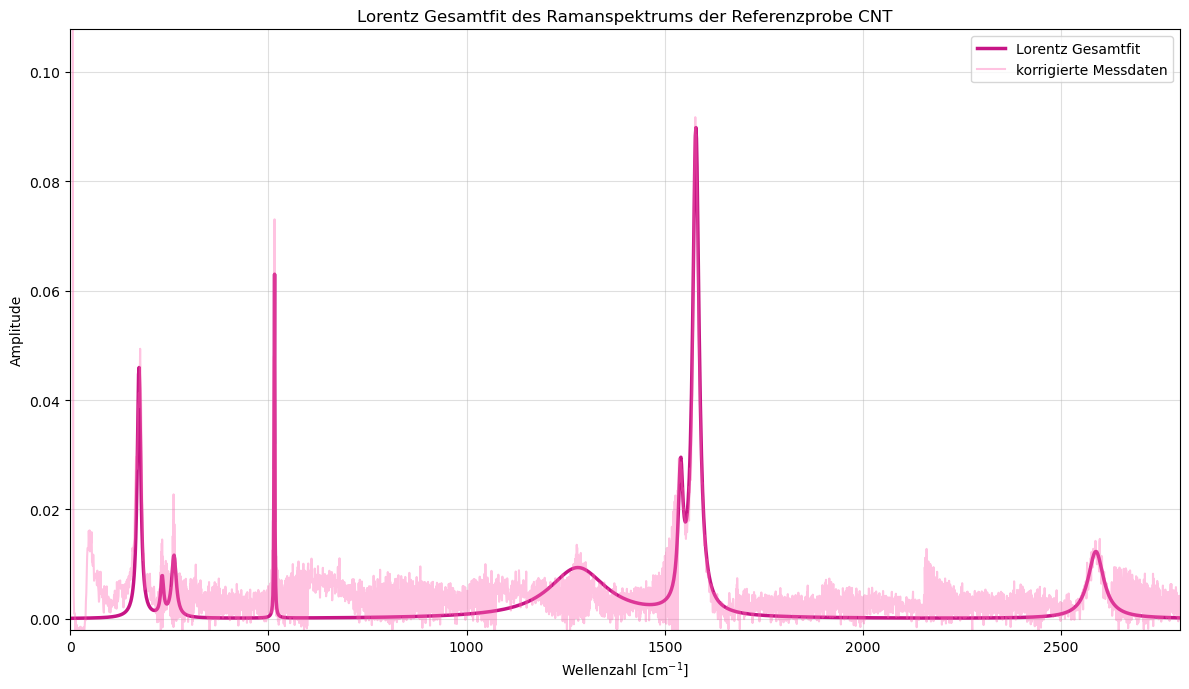

In [63]:
# kontinuierliche x-Achse für den gesamten Messbereich
x_all = np.linspace(0, 2800, 2000)

# Lorentz-Kurven
y_fit_rbm_triple  = triple_lorentz(x_all, *params_rbm_triple)
y_fit_si_to = lorentz(x_all, *params_si_to)

y_fit_d     = lorentz(x_all, popt[0], popt[1], popt[2])
y_fit_g_neg = lorentz(x_all, popt[3], popt[4], popt[5])
y_fit_g_pos = lorentz(x_all, popt[6], popt[7], popt[8]) 

y_fit_2d    = lorentz(x_all, *params_2d)

# Gesamtspektrum = Summe aller einzelnen Fits
y_fit_gesamt = y_fit_rbm_triple + y_fit_si_to + y_fit_d + y_fit_g_neg + y_fit_g_pos + y_fit_2d

# Plot
plt.figure(figsize=(12, 7))
plt.xlim(0, 2800)

max_y = max(np.max(y_fit_gesamt), np.max(y_fit_2d))
plt.ylim(-0.002, max_y * 1.2)

plt.plot(x_all, y_fit_gesamt, color='mediumvioletred', linewidth=2.5, label='Lorentz Gesamtfit')

# mathematischen Peakspitzen markieren
#plt.plot(params_rbm[1], params_rbm[0], marker='o', color='cyan', linestyle='none', label='RBM')
#plt.plot(params_si_to[1], params_si_to[0], marker='o', color='orange', linestyle='none', label='Si-TO')
#plt.plot(popt[1], popt[0], marker='o', color='red', linestyle='none', label='D-Band')
#plt.plot(popt[4], popt[3], marker='o', color='green', linestyle='none', label='G⁻-Band')
#plt.plot(popt[7], popt[6], marker='o', color='purple', linestyle='none', label='G⁺-Band')
#plt.plot(params_2d[1], params_2d[0], marker='o', color='darkorange', linestyle='none', label='2D-Band')

plt.plot(wellenzahl_cm, amplitude - baseline_full, color='hotpink', alpha=0.4, label='korrigierte Messdaten')

plt.title('Lorentz Gesamtfit des Ramanspektrums der Referenzprobe CNT')
plt.xlabel('Wellenzahl [cm$^{-1}$]')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.4)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [64]:
np.savez('fit_daten_kreuz.npz', 
         x_kreuz=wellenzahl_cm, 
         y_kreuz_corr=(amplitude - baseline_full), 
         params_rbm_triple=params_rbm_triple,
         params_si_to=params_si_to,
         popt=popt,
         params_2d=params_2d)